# Experiment No: 2

## Upload and Analyze a CSV Data Set - Preprocessing and Visualization

**Aim:** To upload and analyze the data set given in csv format and perform data preprocessing and visualization.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = {
    'Date': ['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
             '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
             '2023-01-09', '2023-01-10', '2023-01-11', '2023-01-12',
             '2023-01-13', '2023-01-14', '2023-01-15', '2023-01-16'],
    'Product': ['Product A', 'Product B', 'Product A', 'Product C',
                'Product B', 'Product C', 'Product A', 'Product B',
                'Product C', 'Product A', 'Product B', 'Product C',
                'Product A', 'Product B', 'Product C', 'Product C'],
    'Sales': [200, 150, 220, 300, 180, 250, 300, 170,
              270, 290, 160, 260, 340, 190, 280, 240],
    'Quantity': [8, 3, 7, 6, 4, 6, 6, 4,
                 6, 6, 3, 6, 6, 3, 6, 6],
    'Region': ['North', 'South', 'North', 'East', 'West', 'East', 'North',
               'South', 'East', 'North', 'South', 'East', 'North', 'West',
               'East', 'East']
}
df = pd.DataFrame(data)
df.to_csv('sales_data.csv', index=False)
print("sales_data.csv created successfully")

sales_data.csv created successfully


In [2]:
# Load the data into a pandas DataFrame
df = pd.read_csv('sales_data.csv')

# Display the first few rows of the DataFrame
print(df.head())

# Check for missing values
print(df.isnull().sum())

         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         8  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         7  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64


In [3]:
# Summary statistics
print(df.describe())

# Group by product and calculate the total sales and quantity
product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print(product_summary)

            Sales  Quantity
count   16.000000    16.000
mean   237.500000     5.375
std     57.792733     1.500
min    150.000000     3.000
25%    187.500000     4.000
50%    245.000000     6.000
75%    282.500000     6.000
max    340.000000     8.000
     Product  Sales  Quantity
0  Product A   1350        33
1  Product B    850        17
2  Product C   1600        36


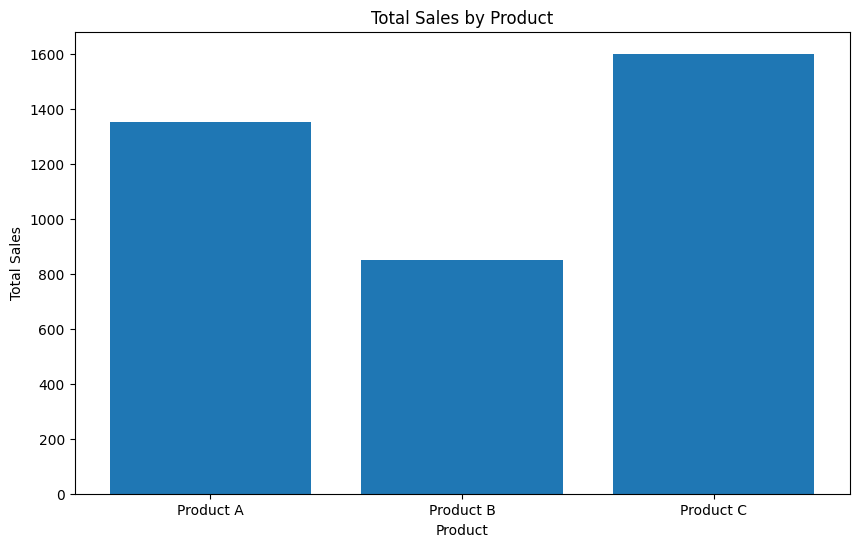

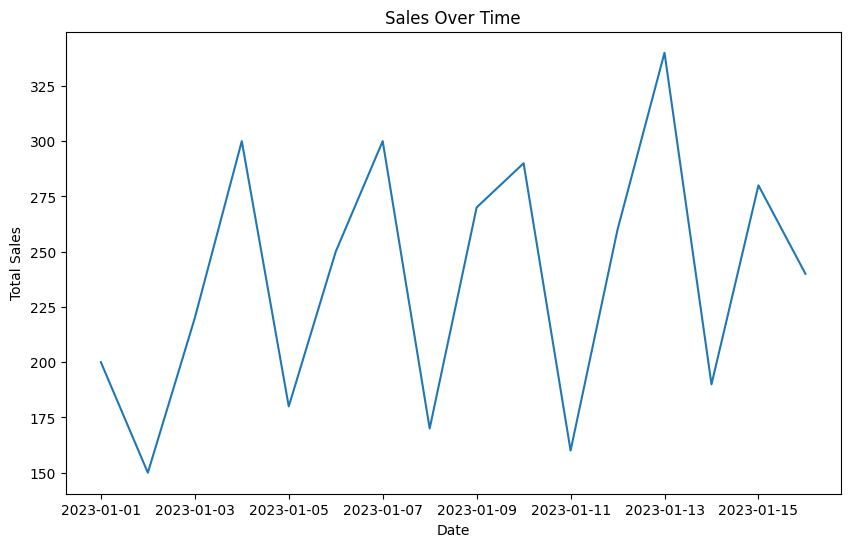

In [4]:
# Bar plot of total sales by product
plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

# Line plot of sales over time
df['Date'] = pd.to_datetime(df['Date'])
sales_over_time = df.groupby('Date').agg({'Sales': 'sum'}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'])
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.show()

Product  Product A  Product B  Product C
Region                                  
East             0          0       1600
North         1350          0          0
South            0        480          0
West             0        370          0
            Sales  Quantity
Sales     1.00000   0.61138
Quantity  0.61138   1.00000


/tmp/ipykernel_2731/1413451212.py:2: FutureWarning: The provided callable <function sum at 0x7f7410719750> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product',


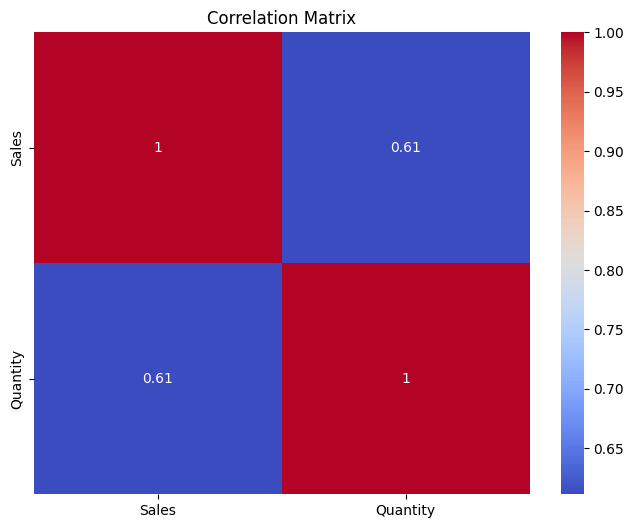

In [5]:
# Pivot table to analyze sales by region and product
pivot_table = df.pivot_table(values='Sales', index='Region', columns='Product',
                             aggfunc=np.sum, fill_value=0)
print(pivot_table)

# Correlation matrix
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

# Heatmap of the correlation matrix
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()